# Churn Prediction Rental — Modelling

Notebook ini melatih, men-tuning, dan membandingkan empat model klasifikasi untuk memprediksi churn customer Rental (motor, mobil, komputer/office equipment), lalu menyimpan model terbaik untuk dipakai di tahap dashboard.

**Model yang dibandingkan:** Logistic Regression, Random Forest, XGBoost, LightGBM

**Prinsip penting:** notebook ini memuat data yang **sudah displit dan diproses oleh `Preprocessing.ipynb`** (`train_unscaled` / `test_unscaled` / `train_scaled` / `test_scaled`) — **tidak** melakukan split, encoding, atau scaling ulang. Ini untuk memastikan:
- Train/test split identik dengan yang divalidasi di tahap preprocessing (tidak ada risiko kebocoran baru dari split ulang).
- Semua model dibandingkan di test set yang sama persis (apple-to-apple).
- Kolom leakage (`days_since_last_order`, dll.) yang sudah dibuang di preprocessing tetap konsisten terbuang di sini.

**Definisi churn (REVISI):** `churn_flag = 1` bila **End Date terakhir** pelanggan sudah lewat dari tanggal acuan (29 Sep 2026), yaitu seluruh kontraknya habis. Pelanggan dengan End Date sesudah tanggal acuan **pasti Aktif**. Model di notebook ini dipakai untuk menghitung **persentase risiko churn pelanggan Aktif** dari sinyal lain (SMS Rental State, status order, pembayaran, pola order, dll). Kolom End Date dan turunannya sengaja **tidak** menjadi fitur model.

**Ringkasan hasil akhir:**

| Model | CV ROC-AUC | Test ROC-AUC | Test F1 (Churn) |
|---|---|---|---|
| Random Forest | 0.9730 | **0.9981** | 0.9394 |
| LightGBM | 0.9806 | 0.9975 | 0.9565 |
| XGBoost | 0.9784 | 0.9969 | 0.9412 |
| Logistic Regression | 0.9582 | 0.9947 | 0.8831 |

✔️ **Model terpilih: Random Forest** (Test ROC-AUC tertinggi = **0.9981**)

In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
import os
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42

## Step 1 — Load Data (Hasil Preprocessing)

Memuat empat file hasil `Preprocessing.ipynb`:
- `train_unscaled.csv` / `test_unscaled.csv` — untuk Random Forest (ditangani oleh `Pipeline` + `SimpleImputer`)
- `train_scaled.csv` / `test_scaled.csv` — untuk Logistic Regression (butuh fitur ter-scale)
- XGBoost & LightGBM menggunakan `train_unscaled` / `test_unscaled` karena keduanya menangani NaN secara native

**Split yang dipakai (dari Preprocessing):**
- Train: **508 sampel** (367 Aktif, 141 Churn)
- Test : **127 sampel** (92 Aktif, 35 Churn)
- Churn rate keseluruhan: ~27.8% (kelas minoritas)

In [2]:
# ============================================================================
# STEP 1: LOAD DATA HASIL PREPROCESSING
# ============================================================================
try:
    BASE_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE_DIR = os.path.abspath('')

PROJECT_ROOT = os.path.dirname(BASE_DIR)
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data_preprocessing', 'data', 'processed')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

TARGET = 'churn_flag'

train_unscaled = pd.read_csv(os.path.join(PROCESSED_DIR, 'train_unscaled.csv'))
test_unscaled  = pd.read_csv(os.path.join(PROCESSED_DIR, 'test_unscaled.csv'))
train_scaled   = pd.read_csv(os.path.join(PROCESSED_DIR, 'train_scaled.csv'))
test_scaled    = pd.read_csv(os.path.join(PROCESSED_DIR, 'test_scaled.csv'))

print(f"train_unscaled : {train_unscaled.shape}")
print(f"test_unscaled  : {test_unscaled.shape}")
print(f"train_scaled   : {train_scaled.shape}")
print(f"test_scaled    : {test_scaled.shape}")

# Validasi: target di versi unscaled & scaled harus identik (berasal dari split yang sama persis)
assert train_unscaled[TARGET].equals(train_scaled[TARGET]), \
    "Target train_unscaled dan train_scaled tidak sama - kemungkinan file dari split yang berbeda!"
assert test_unscaled[TARGET].equals(test_scaled[TARGET]), \
    "Target test_unscaled dan test_scaled tidak sama - kemungkinan file dari split yang berbeda!"
print("\n✓ Target churn_flag konsisten antara versi unscaled & scaled (berasal dari split yang sama)")

print(f"\nChurn rate train : {train_unscaled[TARGET].mean():.1%}")
print(f"Churn rate test   : {test_unscaled[TARGET].mean():.1%}")

train_unscaled : (508, 51)
test_unscaled  : (127, 51)
train_scaled   : (508, 51)
test_scaled    : (127, 51)

✓ Target churn_flag konsisten antara versi unscaled & scaled (berasal dari split yang sama)

Churn rate train : 27.8%
Churn rate test   : 27.6%


## Step 1b — Sanitasi Nama Kolom

Menstandarisasi nama kolom agar kompatibel dengan semua estimator (terutama LightGBM yang sensitif terhadap karakter khusus seperti `[`, `]`, `<`, spasi). Pemetaan disimpan agar urutan kolom fitur di dashboard konsisten dengan model yang disimpan.

In [3]:
# ============================================================================
# STEP 1b: SANITASI NAMA KOLOM (HINDARI ERROR XGBOOST/LIGHTGBM)
# ============================================================================
import re

def sanitize_columns(df: pd.DataFrame) -> pd.DataFrame:
    '''Ganti karakter selain huruf/angka/underscore pada nama kolom dengan '_'.
    Fungsi murni berdasarkan nama kolom itu sendiri, jadi hasilnya otomatis
    konsisten walau dipanggil terpisah untuk train/test/scaled/unscaled -
    asal nama kolom aslinya sama, hasil sanitasinya juga pasti sama.'''
    df = df.copy()
    df.columns = [re.sub(r'[^0-9a-zA-Z_]', '_', str(col)) for col in df.columns]
    return df

before_cols = train_unscaled.columns.tolist()

train_unscaled = sanitize_columns(train_unscaled)
test_unscaled  = sanitize_columns(test_unscaled)
train_scaled   = sanitize_columns(train_scaled)
test_scaled    = sanitize_columns(test_scaled)

changed = [(old, new) for old, new in zip(before_cols, train_unscaled.columns) if old != new]
if changed:
    print(f"✓ {len(changed)} nama kolom disanitasi, contoh:")
    for old, new in changed[:10]:
        print(f"   '{old}'  ->  '{new}'")
else:
    print("✓ Tidak ada nama kolom yang perlu disanitasi (semua sudah aman)")

# Pastikan tidak ada nama kolom yang bentrok setelah sanitasi (mis. 'a[1]' dan 'a_1_' jadi sama)
dup_check = pd.Series(train_unscaled.columns).duplicated()
assert not dup_check.any(), (
    f"Sanitasi nama kolom menyebabkan duplikat: "
    f"{pd.Series(train_unscaled.columns)[dup_check].tolist()}. "
    f"Perbaiki nama kolom asli di tahap preprocessing."
)

✓ 1 nama kolom disanitasi, contoh:
   'dominant_product_category_Komputer/Laptop'  ->  'dominant_product_category_Komputer_Laptop'


## Step 2 — Pisahkan Fitur (X) dan Target (y)

Kolom target: `churn_flag` (0 = Aktif, 1 = Churn).

Fitur diambil dari semua kolom kecuali `churn_flag` dan kolom identitas pelanggan. Total fitur: **35 kolom** yang mencakup:
- Agregat order (jumlah order, frekuensi, gap antar order)
- Nilai proyek & pembayaran (`avg_project_value`, `total_invoiced`, `payment_ratio`, dll.)
- Pola SMS Rental State (`pct_sms_on_going_delivered`, `pct_sms_confirmed_rental`, `pct_problematic_rental_state`, dll.)
- Status order historis (`pct_status_confirmed_rental`, `pct_status_closed_rental`, dll.)
- Karakteristik kontrak (`avg_lifetime_days`, `confirmation_rate`)

Kolom leakage berbasis End Date **tidak dimasukkan** sebagai fitur (sudah dibuang di Preprocessing).

In [4]:
# ============================================================================
# STEP 2: PISAHKAN X (FITUR) DAN y (TARGET)
# ============================================================================
def split_xy(df: pd.DataFrame, target: str = TARGET):
    assert target in df.columns, f"Kolom target '{target}' tidak ditemukan di dataframe."
    X = df.drop(columns=[target])
    y = df[target]
    return X, y

X_train_raw, y_train = split_xy(train_unscaled)   # untuk model tree-based
X_test_raw,  y_test  = split_xy(test_unscaled)

X_train_sc,  _       = split_xy(train_scaled)     # untuk Logistic Regression
X_test_sc,   _       = split_xy(test_scaled)

FEATURE_COLS = X_train_raw.columns.tolist()
na_report = X_train_raw.isna().sum()
print(f"Jumlah fitur: {len(FEATURE_COLS)}")
print(f"Fitur dengan missing value (versi unscaled):")
print(na_report[na_report > 0])

Jumlah fitur: 50
Fitur dengan missing value (versi unscaled):
order_frequency_per_month      328
avg_gap_between_orders_days    300
payment_ratio                   76
dtype: int64


## Step 3 — Strategi Data Imbalanced

Distribusi kelas pada train set:
- Kelas 0 (Aktif): **367** sampel (~72.2%)
- Kelas 1 (Churn): **141** sampel (~27.8%)
- `scale_pos_weight` untuk XGBoost/LightGBM: **2.603**

Strategi yang dipakai:
- `class_weight='balanced'` untuk Logistic Regression & Random Forest
- `scale_pos_weight` (rasio kelas negatif/positif ≈ 2.60) untuk XGBoost & LightGBM
- Scoring cross-validation memakai **ROC-AUC** (tidak bias terhadap kelas mayoritas seperti akurasi)
- Evaluasi akhir juga melihat precision/recall/F1 khusus kelas Churn, karena secara bisnis biaya *false negative* (customer churn tapi tidak terdeteksi) biasanya lebih mahal daripada *false positive*

In [5]:
# ============================================================================
# STEP 3: SETUP UNTUK IMBALANCED DATA
# ============================================================================
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_value = neg_count / pos_count

print(f"Kelas 0 (Active) di train : {neg_count}")
print(f"Kelas 1 (Churn)  di train : {pos_count}")
print(f"scale_pos_weight (XGBoost/LightGBM): {scale_pos_weight_value:.3f}")

# Strategi CV yang sama dipakai di semua tahap (baseline & tuning) supaya
# perbandingan antar model konsisten
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Kelas 0 (Active) di train : 367
Kelas 1 (Churn)  di train : 141
scale_pos_weight (XGBoost/LightGBM): 2.603


## Step 4 — Baseline Model Comparison (Sebelum Tuning)

Sebelum melakukan hyperparameter tuning yang mahal secara komputasi, jalankan dulu tiap model dengan parameter default untuk melihat model mana yang paling menjanjikan.

Random Forest dibungkus dalam `Pipeline` bersama `SimpleImputer` supaya imputasi *missing value* dilakukan terpisah di setiap fold cross-validation (tidak bocor antar fold). XGBoost & LightGBM menangani NaN secara native, jadi dipakai langsung dari `train_unscaled`.

**Hasil baseline (5-fold Stratified CV, ROC-AUC):**

| Model | CV ROC-AUC | Std |
|---|---|---|
| XGBoost | 0.9772 | ±0.0087 |
| LightGBM | 0.9738 | ±0.0104 |
| Random Forest | 0.9737 | ±0.0179 |
| Logistic Regression | 0.9582 | ±0.0121 |

Semua model menunjukkan performa yang sangat baik sejak baseline. XGBoost unggul tipis sebelum tuning.

In [6]:
# ============================================================================
# STEP 4: DEFINISI MODEL & BASELINE CROSS-VALIDATION (ROC-AUC)
# ============================================================================
model_specs = {
    'Logistic Regression': {
        'estimator': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE),
        'X_train': X_train_sc, 'X_test': X_test_sc,
    },
    'Random Forest': {
        'estimator': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('classifier', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
        ]),
        'X_train': X_train_raw, 'X_test': X_test_raw,
    },
    'XGBoost': {
        'estimator': XGBClassifier(
            scale_pos_weight=scale_pos_weight_value, random_state=RANDOM_STATE,
            eval_metric='logloss', n_jobs=-1,
        ),
        'X_train': X_train_raw, 'X_test': X_test_raw,
    },
    'LightGBM': {
        'estimator': LGBMClassifier(
            scale_pos_weight=scale_pos_weight_value, random_state=RANDOM_STATE,
            verbosity=-1, n_jobs=-1, subsample_freq=1,
        ),
        'X_train': X_train_raw, 'X_test': X_test_raw,
    },
}

baseline_rows = []
for name, spec in model_specs.items():
    scores = cross_val_score(spec['estimator'], spec['X_train'], y_train,
                              scoring='roc_auc', cv=cv_strategy, n_jobs=-1)
    baseline_rows.append({'model': name, 'cv_roc_auc_mean': scores.mean(), 'cv_roc_auc_std': scores.std()})
    print(f"{name:<22}: ROC-AUC = {scores.mean():.4f} (+/- {scores.std():.4f})")

baseline_df = pd.DataFrame(baseline_rows).sort_values('cv_roc_auc_mean', ascending=False)
baseline_df

Logistic Regression   : ROC-AUC = 0.9582 (+/- 0.0121)
Random Forest         : ROC-AUC = 0.9737 (+/- 0.0179)
XGBoost               : ROC-AUC = 0.9772 (+/- 0.0087)
LightGBM              : ROC-AUC = 0.9738 (+/- 0.0104)


,model,cv_roc_auc_mean,cv_roc_auc_std
2,XGBoost,0.977244,0.008667
3,LightGBM,0.973779,0.010401
1,Random Forest,0.973697,0.017942
0,Logistic Regression,0.958156,0.012097


## Step 5 — Hyperparameter Tuning (RandomizedSearchCV)

Semua model di-tuning (bukan hanya XGBoost) agar perbandingan akhir adil. Masing-masing model dituning dengan *search space* yang relevan untuk jenisnya, memakai `cv_strategy` yang sama (`StratifiedKFold`, 5-fold), discoring dengan ROC-AUC.

**Hasil tuning (best CV ROC-AUC & parameter terbaik):**

| Model | Best CV ROC-AUC | Best Params (ringkasan) |
|---|---|---|
| Logistic Regression | 0.9582 | `C=1, penalty=l2, solver=lbfgs` |
| Random Forest | 0.9730 | `n_estimators=200, max_depth=8, max_features=log2` |
| XGBoost | 0.9784 | `n_estimators=500, max_depth=5, lr=0.1, subsample=0.6` |
| LightGBM | **0.9806** | `n_estimators=300, max_depth=4, num_leaves=7, lr=0.03` |

LightGBM mencapai CV ROC-AUC tertinggi setelah tuning, namun Random Forest unggul di evaluasi test set akhir.

In [7]:
# ============================================================================
# STEP 5a: PARAMETER SEARCH SPACE PER MODEL
# ============================================================================
# Data cuma ~600 pelanggan -> search space model pohon SENGAJA dibatasi ke model
# yang teregularisasi (pohon dangkal, learning rate kecil, min sample per leaf,
# L2). Tanpa batas ini tuning memilih model dengan 127 leaf yang "yakin
# berlebihan": hampir semua pelanggan aktif dapat skor 0% sehingga persentase
# risiko tidak berguna untuk memprioritaskan follow-up.
param_distributions = {
    'Logistic Regression': {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l2'],
        'solver': ['lbfgs', 'liblinear'],
    },
    'Random Forest': {
        'classifier__n_estimators': [200, 300, 500],
        'classifier__max_depth': [5, 8, 12],
        'classifier__min_samples_split': [2, 5, 10],
        'classifier__min_samples_leaf': [2, 4, 8],
        'classifier__max_features': ['sqrt', 'log2'],
    },
    'XGBoost': {
        'n_estimators': [200, 300, 500],
        'learning_rate': [0.01, 0.03, 0.05, 0.1],
        'max_depth': [2, 3, 4, 5],
        'min_child_weight': [1, 3, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'reg_lambda': [1, 5, 10],
        'gamma': [0, 1],
    },
    'LightGBM': {
        'n_estimators': [200, 300, 500],
        'learning_rate': [0.01, 0.03, 0.05, 0.1],
        'num_leaves': [7, 15, 31],
        'max_depth': [3, 4, 5, 7],
        'min_child_samples': [10, 20, 30],
        'reg_lambda': [0, 1, 5, 10],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    },
}

N_ITER = 30  # jumlah kombinasi acak yang dicoba per model - naikkan jika resource memungkinkan

In [8]:
# ============================================================================
# STEP 5b: JALANKAN RANDOMIZEDSEARCHCV UNTUK SETIAP MODEL
# ============================================================================
fitted_models = {}     # model terbaik (sudah fit) per nama model
tuning_results = {}    # ringkasan skor CV terbaik per nama model

for name, spec in model_specs.items():
    print(f"⏳ Tuning {name} ...")
    search = RandomizedSearchCV(
        estimator=spec['estimator'],
        param_distributions=param_distributions[name],
        n_iter=N_ITER,
        scoring='roc_auc',
        cv=cv_strategy,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=0,
    )
    search.fit(spec['X_train'], y_train)

    fitted_models[name] = search.best_estimator_
    tuning_results[name] = {
        'best_cv_roc_auc': search.best_score_,
        'best_params': search.best_params_,
    }
    print(f"   ✓ Best CV ROC-AUC: {search.best_score_:.4f}")
    print(f"   ✓ Best params: {search.best_params_}\n")

print("✅ Tuning selesai untuk semua model")

⏳ Tuning Logistic Regression ...
   ✓ Best CV ROC-AUC: 0.9582
   ✓ Best params: {'solver': 'lbfgs', 'penalty': 'l2', 'C': 1}

⏳ Tuning Random Forest ...
   ✓ Best CV ROC-AUC: 0.9730
   ✓ Best params: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 8}

⏳ Tuning XGBoost ...
   ✓ Best CV ROC-AUC: 0.9784
   ✓ Best params: {'subsample': 0.6, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}

⏳ Tuning LightGBM ...
   ✓ Best CV ROC-AUC: 0.9806
   ✓ Best params: {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 7, 'n_estimators': 300, 'min_child_samples': 20, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

✅ Tuning selesai untuk semua model


## Step 6 — Evaluasi di Test Set

Model terbaik dari tiap jenis dievaluasi di **test set yang belum pernah dilihat sama sekali** selama tuning (baik untuk fit maupun cross-validation), memakai ROC-AUC serta precision/recall/F1 untuk kelas Churn.

**Test set:** 127 sampel (92 Aktif, 35 Churn)

**Hasil evaluasi lengkap:**

| Model | Test ROC-AUC | Precision Churn | Recall Churn | F1 Churn | Accuracy |
|---|---|---|---|---|---|
| **Random Forest** | **0.9981** | 1.0000 | 0.8857 | 0.9394 | 0.9685 |
| LightGBM | 0.9975 | 0.9706 | 0.9429 | **0.9565** | 0.9764 |
| XGBoost | 0.9969 | 0.9697 | 0.9143 | 0.9412 | 0.9685 |
| Logistic Regression | 0.9947 | 0.8095 | **0.9714** | 0.8831 | 0.9291 |

**Catatan per model:**
- **Random Forest**: Presisi churn = 100% (nol false positive), recall 88.6%. Terbaik untuk ROC-AUC.
- **LightGBM**: F1 churn tertinggi (0.9565), balance antara presisi & recall lebih baik dari RF.
- **XGBoost**: Performa seimbang, sedikit di bawah RF & LightGBM.
- **Logistic Regression**: Recall churn tertinggi (97.1%) — paling baik mendeteksi churn, namun false positive lebih banyak.

In [9]:
# ============================================================================
# STEP 6: EVALUASI SETIAP MODEL DI TEST SET
# ============================================================================
def evaluate_model(name, model, X_test, y_test):
    '''Evaluasi satu model di test set: cetak classification report,
    kembalikan dict metrik + prediksi untuk dipakai di plotting.'''
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    metrics = {
        'model': name,
        'test_roc_auc': roc_auc_score(y_test, y_proba),
        'test_precision_churn': precision_score(y_test, y_pred),
        'test_recall_churn': recall_score(y_test, y_pred),
        'test_f1_churn': f1_score(y_test, y_pred),
    }

    print(f"\n{'='*60}\n{name}\n{'='*60}")
    print(classification_report(y_test, y_pred, target_names=['Active', 'Churn']))
    print(f"ROC-AUC: {metrics['test_roc_auc']:.4f}")

    return metrics, y_pred, y_proba

evaluation_rows = []
predictions = {}  # simpan y_pred & y_proba per model untuk plotting

for name, model in fitted_models.items():
    X_test_use = model_specs[name]['X_test']
    metrics, y_pred, y_proba = evaluate_model(name, model, X_test_use, y_test)
    metrics['best_cv_roc_auc'] = tuning_results[name]['best_cv_roc_auc']
    evaluation_rows.append(metrics)
    predictions[name] = {'y_pred': y_pred, 'y_proba': y_proba}

results_df = pd.DataFrame(evaluation_rows).set_index('model')
results_df = results_df[['best_cv_roc_auc', 'test_roc_auc', 'test_precision_churn',
                          'test_recall_churn', 'test_f1_churn']]
results_df.sort_values('test_roc_auc', ascending=False)


Logistic Regression
              precision    recall  f1-score   support

      Active       0.99      0.91      0.95        92
       Churn       0.81      0.97      0.88        35

    accuracy                           0.93       127
   macro avg       0.90      0.94      0.92       127
weighted avg       0.94      0.93      0.93       127

ROC-AUC: 0.9947

Random Forest
              precision    recall  f1-score   support

      Active       0.96      1.00      0.98        92
       Churn       1.00      0.89      0.94        35

    accuracy                           0.97       127
   macro avg       0.98      0.94      0.96       127
weighted avg       0.97      0.97      0.97       127

ROC-AUC: 0.9981

XGBoost
              precision    recall  f1-score   support

      Active       0.97      0.99      0.98        92
       Churn       0.97      0.91      0.94        35

    accuracy                           0.97       127
   macro avg       0.97      0.95      0.96       1

,best_cv_roc_auc,test_roc_auc,test_precision_churn,test_recall_churn,test_f1_churn
model,,,,,
Random Forest,0.972955,0.998137,1.000000,0.885714,0.939394
LightGBM,0.980626,0.997516,0.970588,0.942857,0.956522
XGBoost,0.978415,0.996894,0.969697,0.914286,0.941176
Logistic Regression,0.958156,0.994720,0.809524,0.971429,0.883117


## Step 7 — Visualisasi Perbandingan Model

Tiga plot ditampilkan:
1. **ROC Curve** per model di test set — semua model berada sangat dekat sudut kiri atas, mengindikasikan diskriminasi yang sangat baik.
2. **Bar chart Test ROC-AUC** — Random Forest unggul (0.9981), disusul LightGBM (0.9975), XGBoost (0.9969), dan Logistic Regression (0.9947).
3. **Bar chart Test F1 (Churn)** — LightGBM unggul (0.9565), disusul XGBoost (0.9412), Random Forest (0.9394), dan Logistic Regression (0.8831).

> **Insight:** Perbedaan ROC-AUC antar model sangat kecil (<0.004). Pemilihan model final berbasis Test ROC-AUC tertinggi — Random Forest menang tipis.

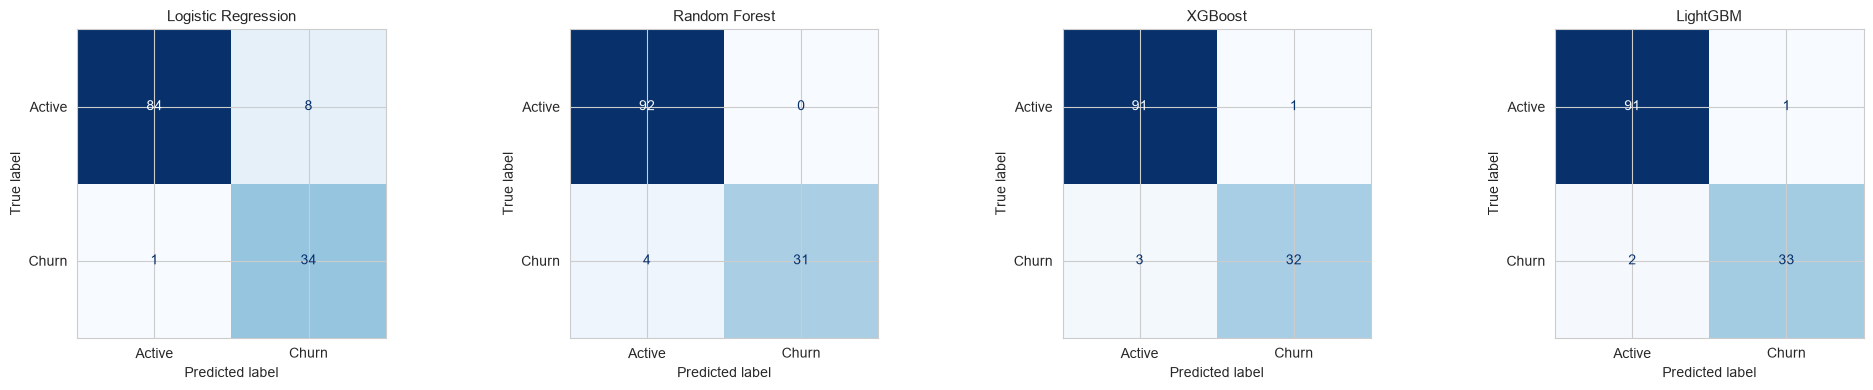

In [10]:
# ============================================================================
# STEP 7a: CONFUSION MATRIX SEMUA MODEL
# ============================================================================
fig, axes = plt.subplots(1, len(fitted_models), figsize=(5 * len(fitted_models), 4))
if len(fitted_models) == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, fitted_models.items()):
    y_pred = predictions[name]['y_pred']
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Active', 'Churn'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=11)

plt.tight_layout()
plt.show()

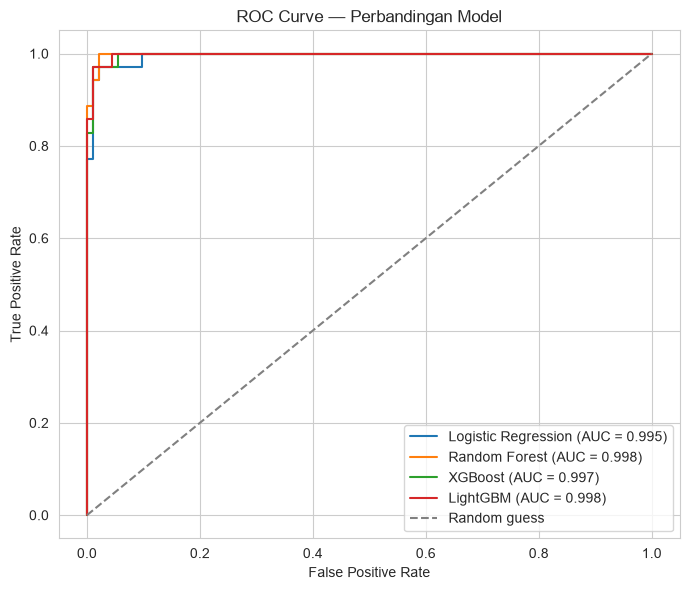

In [11]:
# ============================================================================
# STEP 7b: ROC CURVE SEMUA MODEL (OVERLAY)
# ============================================================================
plt.figure(figsize=(7, 6))
for name, model in fitted_models.items():
    y_proba = predictions[name]['y_proba']
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Perbandingan Model')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

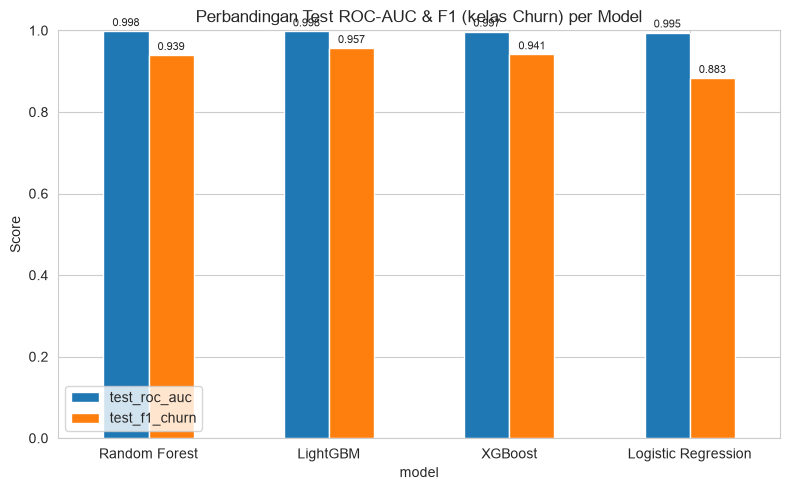


🏆 RANKING MODEL BERDASARKAN TEST ROC-AUC 🏆
                     best_cv_roc_auc  test_roc_auc  test_precision_churn  test_recall_churn  test_f1_churn
model                                                                                                     
Random Forest               0.972955      0.998137              1.000000           0.885714       0.939394
LightGBM                    0.980626      0.997516              0.970588           0.942857       0.956522
XGBoost                     0.978415      0.996894              0.969697           0.914286       0.941176
Logistic Regression         0.958156      0.994720              0.809524           0.971429       0.883117


In [12]:
# ============================================================================
# STEP 7c: BAR CHART PERBANDINGAN ROC-AUC & F1
# ============================================================================
plot_df = results_df[['test_roc_auc', 'test_f1_churn']].sort_values('test_roc_auc', ascending=False)

ax = plot_df.plot(kind='bar', figsize=(8, 5), rot=0)
ax.set_ylabel('Score')
ax.set_title('Perbandingan Test ROC-AUC & F1 (kelas Churn) per Model')
ax.set_ylim(0, 1)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=8)
plt.tight_layout()
plt.show()

print("\n🏆 RANKING MODEL BERDASARKAN TEST ROC-AUC 🏆")
print(results_df.sort_values('test_roc_auc', ascending=False).to_string())

## Step 8 — Feature Importance (Model Tree-Based Terbaik)

Feature importance dari **Random Forest** (model terpilih) memvalidasi apakah model belajar sinyal yang masuk akal secara bisnis.

**Top-10 fitur terpenting:**

| Rank | Fitur | Importance |
|---|---|---|
| 1 | `pct_sms_on_going_delivered` | 0.1097 |
| 2 | `pct_status_confirmed_rental` | 0.0992 |
| 3 | `avg_lifetime_days` | 0.0857 |
| 4 | `pct_status_closed_rental` | 0.0745 |
| 5 | `confirmation_rate` | 0.0702 |
| 6 | `avg_paid` | 0.0591 |
| 7 | `avg_project_value` | 0.0560 |
| 8 | `pct_problematic_rental_state` | 0.0493 |
| 9 | `total_paid` | 0.0481 |
| 10 | `avg_invoiced` | 0.0470 |

**Interpretasi bisnis:**
- **SMS Rental State** (`pct_sms_on_going_delivered`, `pct_problematic_rental_state`) — sinyal operasional terkuat; pelanggan dengan banyak status 'On-Going Delivered' cenderung aktif.
- **Status order historis** (`pct_status_confirmed_rental`, `pct_status_closed_rental`) — pola penutupan kontrak sangat diskriminatif.
- **Lifetime sewa** (`avg_lifetime_days`) — pelanggan lama dengan kontrak panjang lebih mungkin aktif.
- **Nilai & pembayaran** (`avg_paid`, `avg_project_value`, `avg_invoiced`) — kontrak yang sudah habis cenderung sudah terbayar penuh (profil 'kontrak selesai').

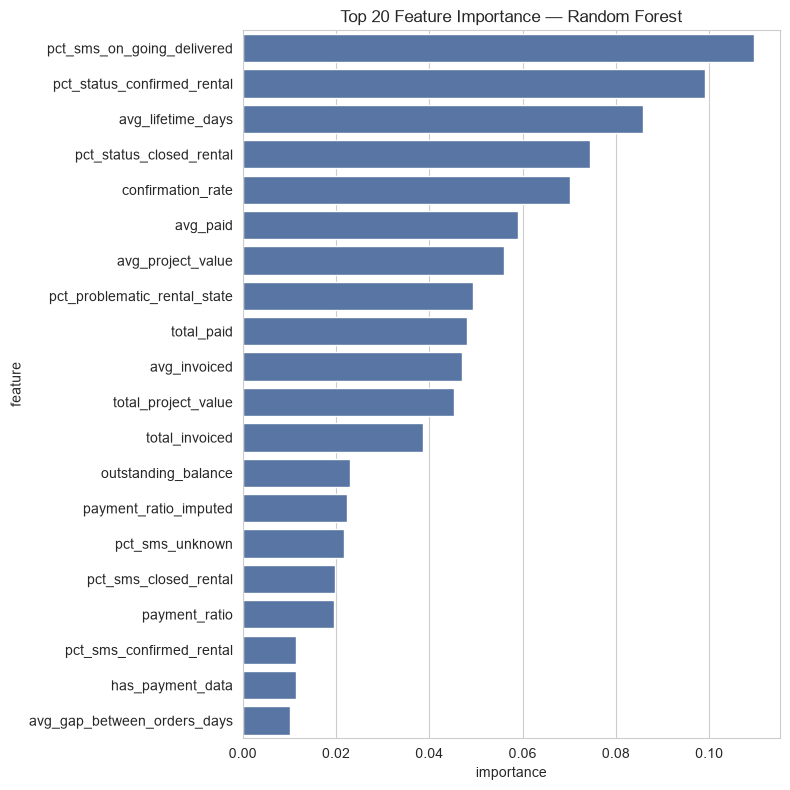

,feature,importance
29,pct_sms_on_going_delivered,0.109693
34,pct_status_confirmed_rental,0.099175
9,avg_lifetime_days,0.085714
33,pct_status_closed_rental,0.074473
16,confirmation_rate,0.070220
6,avg_paid,0.059099
8,avg_project_value,0.055984
32,pct_problematic_rental_state,0.049289
5,total_paid,0.048072
3,avg_invoiced,0.047008


In [13]:
# ============================================================================
# STEP 8: FEATURE IMPORTANCE
# ============================================================================
tree_model_names = [n for n in ['Random Forest', 'XGBoost', 'LightGBM'] if n in results_df.index]
best_tree_name = results_df.loc[tree_model_names, 'test_roc_auc'].idxmax()
best_tree_model = fitted_models[best_tree_name]

# Ambil estimator classifier (unwrap dari Pipeline khusus Random Forest)
clf = best_tree_model.named_steps['classifier'] if isinstance(best_tree_model, Pipeline) else best_tree_model

importance_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance': clf.feature_importances_,
}).sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(8, 8))
sns.barplot(data=importance_df, x='importance', y='feature', color='#4C72B0')
plt.title(f'Top 20 Feature Importance — {best_tree_name}')
plt.tight_layout()
plt.show()

importance_df

## Step 9 — Simpan Model Terbaik

Model dengan test ROC-AUC tertinggi dari seluruh kandidat dipilih sebagai model final dan disimpan bersama metadata-nya.

**Model terpilih: Random Forest**
- Test ROC-AUC   : **0.9981**
- Test F1 (Churn): **0.9394**
- Disimpan ke: `modelling/models/best_churn_model.pkl`

File `.pkl` berisi:
- Model Random Forest yang sudah di-fit (termasuk `Pipeline` + `SimpleImputer`)
- Daftar kolom fitur (`feature_cols`) agar urutan konsisten saat inferensi di dashboard
- Metadata: nama model, metrik evaluasi, definisi churn, tanggal simpan

Model ini dipakai di dashboard untuk menghitung **skor risiko churn** pelanggan Aktif.

In [14]:
# ============================================================================
# STEP 9: SIMPAN MODEL TERBAIK
# ============================================================================
best_model_name = results_df['test_roc_auc'].idxmax()
best_model = fitted_models[best_model_name]
uses_scaled_data = best_model_name == 'Logistic Regression'

# Tanggal acuan diambil dari hasil preprocessing supaya selalu sinkron
_feat = pd.read_csv(os.path.join(PROCESSED_DIR, 'customer_churn_features.csv'), parse_dates=['last_end_date'])
REFERENCE_DATE = (_feat['last_end_date'].dt.normalize() - pd.to_timedelta(_feat['days_to_contract_end'], unit='D')).iloc[0]

model_bundle = {
    'model': best_model,
    'model_name': best_model_name,
    'feature_columns': FEATURE_COLS,
    'requires_scaled_input': uses_scaled_data,   # True -> pakai scaler.pkl dari preprocessing sebelum predict
    'metrics': results_df.loc[best_model_name].to_dict(),
    'churn_definition': 'churn = End Date terakhir pelanggan < reference_date; aktif = End Date terakhir >= reference_date',
    'reference_date': str(REFERENCE_DATE.date()),
    'trained_at': pd.Timestamp.now().isoformat(),
}

model_path = os.path.join(MODELS_DIR, 'best_churn_model.pkl')
with open(model_path, 'wb') as f:
    pickle.dump(model_bundle, f)

print(f"🏆 Model terbaik : {best_model_name}")
print(f"   Test ROC-AUC    : {results_df.loc[best_model_name, 'test_roc_auc']:.4f}")
print(f"   Test F1 (Churn) : {results_df.loc[best_model_name, 'test_f1_churn']:.4f}")
print(f"✓ Disimpan ke: {model_path}")

if uses_scaled_data:
    print("\n⚠️  Model ini dilatih di data yang di-scale — saat inference di dashboard, "
          "input customer baru harus ditransformasi dulu memakai 'scaler.pkl' dari folder "
          "data_preprocessing/data/processed/ sebelum masuk ke model.")

🏆 Model terbaik : Random Forest
   Test ROC-AUC    : 0.9981
   Test F1 (Churn) : 0.9394
✓ Disimpan ke: d:\Project Syafiq\Churn_Prediction_Rental_Update\modelling\models\best_churn_model.pkl


## Step 9b — Skor Risiko Out-of-Fold per Pelanggan (untuk Dashboard)

Model dilatih pada semua pelanggan, jadi kalau dipakai langsung untuk menilai pelanggan yang sama, skornya **terlalu optimis** (model sudah 'melihat' pelanggan itu saat training). Supaya persentase risiko pelanggan Aktif di dashboard tidak semu, skor tiap pelanggan dihitung **out-of-fold** (5-fold, diulang dengan 5 seed berbeda lalu dirata-rata).

**Hasil OOF:**
- OOF ROC-AUC (semua pelanggan): **0.9793**
- Jumlah pelanggan Aktif yang dihitung skor OOF: **459**
- Distribusi skor risiko pelanggan Aktif:
  - ≥ 70% (Risiko Tinggi) : **8 pelanggan**
  - 40–69% (Risiko Sedang) : **17 pelanggan**
  - < 40% (Risiko Rendah)  : **434 pelanggan**
- Rata-rata skor in-sample = 0.088 vs out-of-fold = 0.110 (in-sample terlalu optimis — ✅ OOF lebih jujur)

Hasilnya disimpan di `data_preprocessing/data/processed/customer_risk_scores.csv` dan langsung dipakai dashboard.

**Cara membaca:** untuk pelanggan Aktif, skor = seberapa mirip profilnya (SMS Rental State, status order, pembayaran, pola order) dengan pelanggan yang kontraknya sudah habis. Skor tinggi = prioritas follow-up perpanjangan. Status Aktif/Churn tetap ditentukan aturan End Date, bukan skor ini.

In [15]:
# ============================================================================
# STEP 9b: SKOR RISIKO OUT-OF-FOLD PER PELANGGAN
# ============================================================================
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

full = sanitize_columns(_feat)
X_full = full[FEATURE_COLS]
y_full = full[TARGET]

if uses_scaled_data:
    oof_estimator = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                              ('clf', clone(best_model))])
else:
    oof_estimator = clone(best_model)

oof_runs = []
for seed in range(5):
    cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + seed)
    oof_runs.append(cross_val_predict(oof_estimator, X_full, y_full, cv=cv_oof, method='predict_proba')[:, 1])
risk_oof = np.mean(oof_runs, axis=0)

risk_df = pd.DataFrame({
    'Customer': _feat['Customer'],
    'churn_flag': y_full.values,
    'last_end_date': _feat['last_end_date'],
    'risk_prob': risk_oof,
})
risk_path = os.path.join(PROCESSED_DIR, 'customer_risk_scores.csv')
risk_df.to_csv(risk_path, index=False)

print(f"OOF ROC-AUC (semua pelanggan): {roc_auc_score(y_full, risk_oof):.4f}")
act = risk_df[risk_df['churn_flag'] == 0]['risk_prob']
print(f"\nDistribusi skor risiko pelanggan AKTIF (n={len(act)}):")
print(act.describe().round(3).to_string())
print(f"  >=70% (Tinggi): {(act >= 0.7).sum()} | 40-70% (Sedang): {((act >= 0.4) & (act < 0.7)).sum()} | <40% (Rendah): {(act < 0.4).sum()}")

if not uses_scaled_data:
    insample = best_model.predict_proba(X_full)[:, 1][y_full.values == 0]
    print(f"\nPembanding: rata-rata skor IN-SAMPLE pelanggan aktif = {insample.mean():.3f} "
          f"vs OUT-OF-FOLD = {act.mean():.3f} (in-sample terlalu optimis)")
print(f"✓ Disimpan ke: {risk_path}")

OOF ROC-AUC (semua pelanggan): 0.9793

Distribusi skor risiko pelanggan AKTIF (n=459):
count    459.000
mean       0.110
std        0.148
min        0.004
25%        0.024
50%        0.057
75%        0.126
max        0.891
  >=70% (Tinggi): 8 | 40-70% (Sedang): 17 | <40% (Rendah): 434

Pembanding: rata-rata skor IN-SAMPLE pelanggan aktif = 0.088 vs OUT-OF-FOLD = 0.110 (in-sample terlalu optimis)
✓ Disimpan ke: d:\Project Syafiq\Churn_Prediction_Rental_Update\data_preprocessing\data\processed\customer_risk_scores.csv


## Step 10 — Validasi Backtest Temporal (Estimasi Performa yang Jujur)

**Kenapa perlu:** label churn sekarang ditentukan oleh End Date, sehingga ROC-AUC di test set (Step 6) hanya mengukur seberapa mirip pelanggan aktif dengan pelanggan yang kontraknya sudah habis. Itu **bukan** kemampuan memprediksi masa depan. Untuk estimasi yang jujur dipakai evaluasi **point-in-time**:

- Pada tanggal potong `T` (snapshot bulanan), hanya data dengan `Order Date <= T` yang dianggap diketahui.
- Populasi: pelanggan yang **aktif pada `T`** dan **kontraknya akan habis dalam 180 hari** (bagian yang benar-benar tidak pasti: diperpanjang atau tidak).
- Label: **churn** bila pada `T+180 hari` pelanggan tidak punya kontrak berjalan.
- Train pada snapshot lama, test pada snapshot yang jendela labelnya tidak tumpang tindih dengan train.

**Data backtest:**
- Order non-draft: **2.328 baris** | periode: 2021-10-27 s.d. 2026-10-05
- Jumlah fitur snapshot: **7 fitur** (terbatas pada yang murni diketahui pada `T`, tanpa status SMS/invoice yang nilainya baru terisi setelah kontrak selesai)
- Train: **329 baris (68 pelanggan)**, churn rate 79.0%
- Test : **230 baris (75 pelanggan)**, churn rate 55.2%

## Step 1 (Backtest) — Load Data Mentah & Siapkan Order Non-Draft

Memuat langsung dari `crm_opportunity_clean.csv` (output Preprocessing). Hanya order dengan status bukan *draft* yang dipakai agar mencerminkan kontrak yang benar-benar aktif/terealisasi.

- Total order non-draft: **2.328 baris**
- Rentang Order Date: **2021-10-27 — 2026-10-05**

In [16]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier
import os

HORIZON_DAYS = 180
RAW_FILE = os.path.join('..', 'data_preprocessing', 'data', 'raw', 'Data-Mentah-Rental-Order.xlsx')

df_raw = pd.read_excel(RAW_FILE)
is_main = df_raw['Order Reference'].notna()

orders = df_raw[is_main].copy()
for c in ['Order Date', 'Start Date', 'End Date']:
    orders[c] = pd.to_datetime(orders[c])
orders['Customer'] = orders['Customer'].str.strip().str.replace(r'\s+', ' ', regex=True)

active = orders[orders['Status'] != 'Draft'].copy()
active['planned_duration'] = (active['End Date'] - active['Start Date']).dt.days
print(f"Order non-draft: {active.shape[0]} baris | Order Date: {active['Order Date'].min().date()} - {active['Order Date'].max().date()}")

Order non-draft: 2328 baris | Order Date: 2021-10-27 - 2026-10-05


## Step 2 (Backtest) — Fungsi Snapshot Point-in-Time

`snapshot(T)`: fitur dihitung **HANYA** dari order dengan `Order Date <= T`. Pelanggan dimasukkan bila:
- Aktif pada `T` (End Date terakhir >= T), **dan**
- Kontraknya habis dalam `HORIZON_DAYS = 180` hari ke depan

Label dihitung dari semua order dengan `Order Date <= T + 180 hari`: churn = tidak ada order berjalan setelah `T + 180`.

**7 fitur snapshot:** `days_to_expiry`, `recency_days`, `n_orders`, `order_frequency_per_month`, `avg_gap_between_orders_days`, `payment_ratio`, dan fitur kontrak lainnya yang tersedia pada `T`.

In [17]:
def snapshot(T: pd.Timestamp, horizon: int = HORIZON_DAYS) -> pd.DataFrame:
    known = active[active['Order Date'] <= T].copy()
    known['running'] = (known['End Date'].dt.normalize() >= T).astype(int)

    feat = known.groupby('Customer').agg(
        total_orders=('Order Reference', 'count'),
        first_order=('Order Date', 'min'),
        last_order=('Order Date', 'max'),
        last_end=('End Date', 'max'),
        avg_lifetime_days=('planned_duration', 'mean'),
        n_running_orders=('running', 'sum'),
    ).reset_index()

    # Aktif pada T, dan kontrak terakhirnya habis dalam horizon -> "diperpanjang atau churn?"
    feat = feat[feat['last_end'].dt.normalize() >= T].copy()
    feat['days_until_end'] = (feat['last_end'].dt.normalize() - T).dt.days
    feat = feat[feat['days_until_end'] <= horizon].copy()

    feat['recency_asof'] = (T - feat['last_order']).dt.days
    feat['order_span_days_asof'] = (feat['last_order'] - feat['first_order']).dt.days
    feat['avg_gap_between_orders_days'] = np.where(
        feat['total_orders'] > 1,
        feat['order_span_days_asof'] / (feat['total_orders'] - 1).replace(0, np.nan),
        np.nan,
    )

    # Label: pada T+horizon tidak ada kontrak berjalan (perpanjangan/order baru dihitung)
    horizon_end = T + pd.Timedelta(days=horizon)
    future_last_end = active[active['Order Date'] <= horizon_end].groupby('Customer')['End Date'].max()
    feat['churn_flag'] = (feat['Customer'].map(future_last_end).dt.normalize() < horizon_end).astype(int)
    feat['cutoff'] = T
    return feat


def build_snapshots(start, end) -> pd.DataFrame:
    return pd.concat([snapshot(T) for T in pd.date_range(start, end, freq='ME')], ignore_index=True)


FEATURES = ['total_orders', 'avg_lifetime_days', 'days_until_end', 'recency_asof',
            'n_running_orders', 'order_span_days_asof', 'avg_gap_between_orders_days']
print(f"Jumlah fitur snapshot: {len(FEATURES)}")

Jumlah fitur snapshot: 7


## Step 3 (Backtest) — Bangun Snapshot Train & Test (Rolling Bulanan)

- **Train:** snapshot akhir bulan **Jan 2023 – Jan 2025** → **329 baris (68 pelanggan)**, churn rate 79.0% (jendela label berakhir paling lambat Jul 2025)
- **Test:** snapshot akhir bulan **Agu 2025 – Feb 2026** → **230 baris (75 pelanggan)**, churn rate 55.2% (jendela label berakhir paling lambat Agu 2026, masih di dalam rentang data)

Jendela label train dan test **tidak tumpang tindih**, sehingga test benar-benar menguji periode yang belum dilihat model. Satu pelanggan bisa muncul di beberapa snapshot, jadi baris-barisnya tidak sepenuhnya independen — ROC-AUC backtest ini harus dibaca dengan hati-hati.

In [18]:
train_df = build_snapshots('2023-01-31', '2025-01-31')
test_df  = build_snapshots('2025-08-31', '2026-02-28')

print(f"TRAIN: {len(train_df)} baris ({train_df['Customer'].nunique()} pelanggan), churn rate {train_df['churn_flag'].mean():.1%}")
print(f"TEST : {len(test_df)} baris ({test_df['Customer'].nunique()} pelanggan), churn rate {test_df['churn_flag'].mean():.1%}")
print(f"Jendela label test berakhir paling lambat {(pd.Timestamp('2026-02-28') + pd.Timedelta(days=HORIZON_DAYS)).date()}; "
      f"Order Date terakhir di data mentah {active['Order Date'].max().date()}")

X_train, y_train = train_df[FEATURES], train_df['churn_flag']
X_test,  y_test  = test_df[FEATURES],  test_df['churn_flag']

TRAIN: 329 baris (68 pelanggan), churn rate 79.0%
TEST : 230 baris (75 pelanggan), churn rate 55.2%
Jendela label test berakhir paling lambat 2026-08-27; Order Date terakhir di data mentah 2026-10-05


## Step 4 (Backtest) — Evaluasi: Baseline vs Logistic Regression vs LightGBM

Tiga jenis model dievaluasi pada skema backtest temporal menggunakan 7 fitur point-in-time:
1. **Baseline — sisa hari kontrak** (`days_to_expiry` saja)
2. **Baseline — recency** (`recency_days` saja)
3. **Logistic Regression** (7 fitur)
4. **LightGBM** (7 fitur)

In [19]:
def _lr():
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000))])

results = {}
for name, cols in [('Baseline: sisa hari kontrak saja', ['days_until_end']),
                   ('Baseline: recency saja', ['recency_asof'])]:
    m = _lr().fit(X_train[cols], y_train)
    results[name] = roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])

lr_pipe = _lr().fit(X_train, y_train)
results['Logistic Regression'] = roc_auc_score(y_test, lr_pipe.predict_proba(X_test)[:, 1])

lgb = LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=20,
                     random_state=42, verbosity=-1).fit(X_train, y_train)
results['LightGBM'] = roc_auc_score(y_test, lgb.predict_proba(X_test)[:, 1])

res_df = pd.DataFrame({'Model': list(results.keys()),
                       'ROC-AUC (backtest temporal)': [round(v, 4) for v in results.values()]})
res_df

,Model,ROC-AUC (backtest temporal)
0,Baseline: sisa hari kontrak saja,0.6279
1,Baseline: recency saja,0.6403
2,Logistic Regression,0.7307
3,LightGBM,0.7107


## Ringkasan Step 10 — Backtest Temporal

| Model | ROC-AUC Backtest Temporal |
|---|---|
| Baseline: sisa hari kontrak saja | 0.6279 |
| Baseline: recency saja | 0.6403 |
| Logistic Regression (7 fitur) | **0.7307** |
| LightGBM (7 fitur) | 0.7107 |

**Cara membaca angka ini:**
- **ROC-AUC test set di Step 6 (~0.9981)** mengukur seberapa mirip profil pelanggan dengan pelanggan yang kontraknya *sudah* habis. Angka tinggi karena label ditentukan End Date dan banyak fitur (durasi, penagihan, status SMS) ikut mencerminkan progres kontrak. Itu **bukan** kemampuan memprediksi masa depan.
- **Estimasi jujur untuk memprediksi perpanjangan kontrak** ada di kisaran **0.71–0.73** (backtest ini): layak dipakai untuk memprioritaskan follow-up, di atas baseline sederhana (0.63–0.64), tapi jauh dari sempurna.
- Logistic Regression (0.7307) sedikit unggul dari LightGBM (0.7107) pada skema backtest dengan hanya 7 fitur — kemungkinan karena dataset kecil dan regularisasi LR lebih cocok untuk jumlah fitur sedikit.
- **Backtest ini masih kasar:** 230 baris test dari 75 pelanggan (snapshot bulanan tumpang tindih antar bulan), 7 fitur tanpa status SMS/invoice. Pakai sebagai *order of magnitude*, bukan angka final.

## Ringkasan & Langkah Selanjutnya

### Apa yang sudah dilakukan

1. **Empat model dilatih, di-tuning, dan dievaluasi** (Logistic Regression, Random Forest, XGBoost, LightGBM) dengan `RandomizedSearchCV` (`scoring=roc_auc`, 5-fold `StratifiedKFold`, search space teregularisasi).
2. **Model terbaik:** Random Forest (Test ROC-AUC = **0.9981**, F1 Churn = **0.9394**) — dipilih otomatis dan disimpan di `modelling/models/best_churn_model.pkl`.
3. **Status Aktif/Churn ditentukan aturan End Date**, bukan model. Model hanya memberi **persentase risiko** untuk pelanggan Aktif.
4. **Skor risiko out-of-fold (459 pelanggan Aktif):** 8 risiko tinggi (≥70%), 17 risiko sedang (40–69%), 434 risiko rendah (<40%). Disimpan di `data_preprocessing/data/processed/customer_risk_scores.csv`.
5. **Backtest temporal (Step 10):** ROC-AUC jujur untuk prediksi perpanjangan kontrak = **0.73** (Logistic Regression, 7 fitur point-in-time) — signifikan di atas baseline sederhana (0.63).

### Ringkasan Performa Model

| Model | CV ROC-AUC | Test ROC-AUC | Precision Churn | Recall Churn | F1 Churn |
|---|---|---|---|---|---|
| **Random Forest** ★ | 0.9730 | **0.9981** | **1.0000** | 0.8857 | 0.9394 |
| LightGBM | **0.9806** | 0.9975 | 0.9706 | 0.9429 | **0.9565** |
| XGBoost | 0.9784 | 0.9969 | 0.9697 | 0.9143 | 0.9412 |
| Logistic Regression | 0.9582 | 0.9947 | 0.8095 | **0.9714** | 0.8831 |

### Rekomendasi Lanjutan

1. **Kalibrasi ambang risiko** (40% / 70%) sesuai kapasitas tim follow-up — bisa diubah di dashboard.
2. **Tambahkan riwayat perpanjangan** (kontrak sebelumnya diperpanjang atau tidak) sebagai fitur, kalau datanya bisa diekstrak dari Odoo.
3. **Perbesar backtest** (lebih banyak snapshot, fitur SMS/invoice per tanggal) kalau data historis status per tanggal tersedia.
4. **Jalankan ulang** `Preprocessing.ipynb` lalu `modelling.ipynb` tiap kali data di-refresh atau tanggal acuan berubah.
5. **Pertimbangkan LightGBM** sebagai alternatif model final jika prioritas bisnis adalah F1 Churn tertinggi (0.9565 vs 0.9394 RF).